<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_009_SVM_maquinas_de_soporte_vectorial/05_SVM_SKLearn_Cuatro_Categorias_2_dimensiones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Máquina de Soporte Vectorial

En este ejemplo usaremos los datos de diferenciación niños/adultos usando estatura y peso, y aplicaremos distancia euclidiana.

Text(0, 0.5, 'Peso en kilogramos')

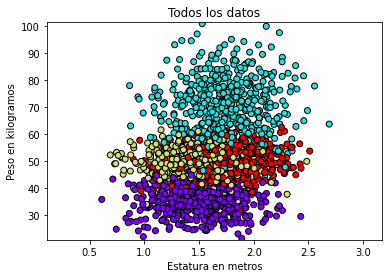

In [ ]:
from sklearn.datasets import make_blobs
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

X, y = make_blobs(n_samples=[500,500,500,500],
                  n_features = 4,
                  centers=[[1.50,35],[1.75,70],[1.50,50],[1.75,50]],
                  cluster_std = [[0.3,5],[0.3,10],[0.3,4.5],[0.3,4.5]],
                  random_state=1970)
y = y+1.0
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = 0.02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                      np.arange(y_min, y_max, h))

# just plot the dataset first
cm = plt.cm.rainbow
cm_bright = cm
#cm_bright = ListedColormap(['#FF0000', '#0000FF','#0FF000', '#000000'])
ax = plt.figure()
plt.title("Todos los datos")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")


El ejemplo lo basaremos en datos simulados que representan\
una población de personas de género masculino\
niños y adultos, y se tienen dos características de ellos: estatura y peso

Dado que las escalas de peso y estaturas son muy diferentes
(dos ordenes de magnitud)
Antes de aplicar el clasificador, debemos llevarlas
a la misma escala:
* Se resta la media
* Se divide por la desviación estándar


In [ ]:
from sklearn import preprocessing
#X_estandarizada = X
X_estandarizada = preprocessing.scale(X)
X = X_estandarizada

Y volvemos a mostrar los datos ...

Text(0, 0.5, 'Peso en kilogramos')

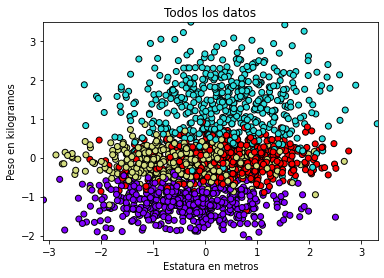

In [ ]:
x_min, x_max = X[:, 0].min() - .01, X[:, 0].max() + .01
y_min, y_max = X[:, 1].min() - .01, X[:, 1].max() + .01
h = 0.02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                      np.arange(y_min, y_max, h))

# just plot the dataset first
#cm = plt.cm.RdBu
#cm_bright = ListedColormap(['#FF0000', '#0000FF','#0FF000', '#000000'])
ax = plt.figure()
plt.title("Todos los datos")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")

Ahora creamos los datos de prueba y entrenamiento

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = \
    train_test_split(X, y, test_size=0.33, random_state=1970)

In [ ]:
from sklearn.svm import SVC

clfSVC = SVC(
    kernel = 'poly',#'sigmoid', # ‘linear’, ‘poly’, ‘rbf’
    probability = True
    )

clfSVC.fit(X_train,y_train)
y_esperado = y_test
y_predicho = clfSVC.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_esperado,y_predicho))

0.7166666666666667


(90440, 4)


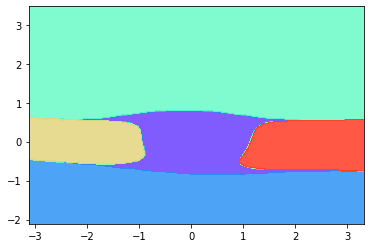

In [ ]:
ZT =clfSVC.predict_proba(np.c_[xx.ravel(), yy.ravel()])
print(ZT.shape)
ZT[ZT<0.5]=0.0
ZT[ZT>=0.5]=1.0
ZT[:, 1]=ZT[:, 1]*2.0
ZT[:, 2]=ZT[:, 2]*3.0
ZT[:, 3]=ZT[:, 3]*4.0
Z = ZT[:, 0]+ZT[:, 1]+ZT[:, 2]+ZT[:, 3]
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure()
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8)

Y esto es lo que el sistema sabe